# Phase 5: deep KiL (policy graph as a training signal, LoRA on Qwen3-8B)

**Goal:** the deep level of RQ2 and Hypothesis 1 (H1), as in the project proposal: *fine-tune a small open model (7–8B, LoRA) on agent trajectories, adding a loss that penalizes actions whose graph preconditions are unmet.* Question: does **learning** the constraints beat **checking** them at runtime?

**Why not Gemini:** deep KiL changes the model's weights with my own loss. `gemini-3.1-flash-lite` is API-only: I can't get its weights, and Google's tuning (where offered) is standard supervised tuning, so I can't add the penalty term. So the agent here is an open model, Qwen3-8B. The τ-bench paper itself did no fine-tuning; it lists "domain-specific fine-tuning or agent code scaffolding" as future work, and it skipped 7/13B models as too weak for the benchmark.

**Training data** (`deep_data.py`), from the 1,600 Gemini dialogues of 05G–08:
- **positive** = a dialogue that passed **and** broke no data rule (the proposal: "filtered to successful and policy-compliant runs")
- **negative** = one write call that broke a data rule (found by the 06G checker), with the dialogue before it
- the system prompt is always the prose `wiki.md`: here the graph lives in the weights, not in the prompt

**Loss** (`deep_train.py`): normal next-token loss on the agent's turns of positives **+ 0.5 × unlikelihood** of each violating call, `-log(1 - p(call))`. The negatives come from the policy graph, so this is the "graph as training signal".

**No test leakage:** τ-bench airline has only the 50 test tasks (`tasks.py` repeats 42 of them). So I split **by task into 5 folds** (task t is in fold t % 5). The adapter that answers a task never saw that task in training.

**Arms** (all: agent = Qwen3-8B on vLLM, user = the same Gemini simulator as 05G–08):

| arm | agent | role |
|---|---|---|
| `qwen_base` | Qwen3-8B, no training | baseline for this model |
| `qwen_sft` | + LoRA, fine-tuning only (penalty 0) | ablation: is it the penalty or just the data? |
| `qwen_deep` | + LoRA, fine-tuning + violation penalty | **deep KiL** |
| `qwen_validator` | Qwen3-8B + the 06G validator | H1 control on the same model |

**Limits I note:** the penalty covers only the 24 data rules (the checker can't see the 5 dialogue rules); the agent model differs from 05G–08, so 09 is compared inside its own arms, and Gemini numbers are shown only for reference.

**Runtime:** GPU with ≥ 40 GB (A100 or H100; T4 and L4 are too small). Training: 10 adapters (5 folds × 2 modes). **Cost:** only the Gemini user simulator is paid; the pilot (cell 15) measures it before the full run.

**Run first:** 05G–08 (results + `settings_gemini.py`, `policy_checker.py`, `violations.py`, `passk.py`).

**Result (done):** deep KiL pass^1 0.340, pass^8 0.12: above the base model and plain fine-tuning at every k (significant), below the validator (not significant); violations 349 → 76. Hypothesis 1 is not supported. See the Summary at the end.

In [2]:
# mount Google Drive so results are saved
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
# install tau-bench, vLLM and PEFT (GPU runtime)
%cd /content/drive/MyDrive/cmsc691-10-project2
!pip install -q -e .
!pip install -q mcp vllm peft
!pip uninstall -y torchao
print("installed")

/content/drive/MyDrive/cmsc691-10-project2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau_bench (pyproject.toml) ... done
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
installed


In [4]:
# load settings, set the Gemini key, check the GPU and the files 09 needs
import os, sys, importlib, logging, warnings
import pandas as pd
from IPython.display import display
os.chdir("/content/drive/MyDrive/cmsc691-10-project2"); sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-project2")
warnings.filterwarnings("ignore"); logging.getLogger("LiteLLM").setLevel(logging.ERROR)
for f in ["settings_gemini.py", "policy_checker.py", "violations.py", "passk.py", "airline_policy_graph.json",
          "results_gemini_baseline", "results_gemini_validator", "results_gemini_shallow", "results_gemini_semideep"]:
    assert os.path.exists(f), f"{f} missing: run 04-08 first"
importlib.invalidate_caches()
import settings_gemini; importlib.reload(settings_gemini)
from settings_gemini import MODEL, ENV, N_TASKS, N_TRIALS, CONCURRENCY, PRICE_IN, PRICE_OUT

def set_token():
    from google.colab import userdata
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")   # never printed
set_token()

import torch
assert torch.cuda.is_available(), "no GPU: Runtime > Change runtime type > A100 or H100"
gb = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU: {torch.cuda.get_device_name(0)}, {gb:.0f} GB", "" if gb >= 39 else " <- too small, need >= 40 GB")
print(f"user simulator: {MODEL}")

GPU: NVIDIA A100-SXM4-40GB, 42 GB 
user simulator: gemini-3.1-flash-lite


In [5]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/settings_deep.py
# frozen settings for 09 deep KiL (LoRA on an open model)
# The user simulator stays the same as every Gemini arm (settings_gemini.py),
# so the only thing that changes between 09 arms is the agent.
BASE_MODEL = "Qwen/Qwen3-8B"        # 7-8B open model, as in the project proposal
SERVED_BASE = "qwen3-8b"            # name of the base model on the vLLM server
AGENT_THINKING = False              # training data has no thinking, so the agent does not think
AGENT_MAX_TOKENS = 4096             # cap on one agent reply
MAX_MODEL_LEN = 32768               # vLLM max model length
GPU_MEM = "0.85"                    # vLLM gpu-memory-utilization

# training data: Gemini dialogues from 05G-08 (same tasks, so I split by task)
SOURCE_DIRS = ["results_gemini_baseline", "results_gemini_validator",
               "results_gemini_shallow", "results_gemini_semideep"]
N_FOLDS = 5                         # fold of task t = t % 5; a task is never tested by a model trained on it
MAX_POS_PER_TASK = 8                # cap on good dialogues per task, so easy tasks don't dominate
MAX_TRAIN_LEN = 16384               # skip longer examples (tokens)

# LoRA
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LR = 1e-4
EPOCHS = 1
GRAD_ACCUM = 8
PENALTY = 0.5                       # weight of the violation penalty (0 = plain fine-tuning)
SEED = 0

Overwriting /content/drive/MyDrive/cmsc691-10-project2/settings_deep.py


In [6]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/deep_data.py
# Training data for deep KiL, built from the Gemini dialogues of 05G-08.
#   positive = a dialogue that passed AND broke no data rule (the proposal:
#              "filtered to successful and policy-compliant runs")
#   negative = one write call that broke a data rule, with the dialogue before it
#              (the loss pushes its probability down)
# Every example keeps its task id, so training for fold f can leave out
# the tasks of fold f (they are the test tasks of that fold).
import json
import os
import random
from collections import Counter

import passk
import policy_checker as pc
import violations as V
from settings_deep import SOURCE_DIRS, N_FOLDS, MAX_POS_PER_TASK, SEED
from tau_bench.envs.airline.data import load_data
from tau_bench.envs.airline.tools import ALL_TOOLS
from tau_bench.envs.airline.wiki import WIKI

TOOLS_INFO = [t.get_info() for t in ALL_TOOLS]
N_TASKS = 50


def fold_of(task):
    return task % N_FOLDS


def fold_tasks(f):
    return [t for t in range(N_TASKS) if fold_of(t) == f]


def scan(traj, graph):
    """Indexes of assistant messages whose write call broke a data rule.
    Same replay as violations.replay, but it keeps the message index."""
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    data, hist, bad = load_data(), [], []
    for i, m in enumerate(traj):
        if m.get("role") != "assistant" or not m.get("tool_calls"):
            continue
        c = m["tool_calls"][0]
        if c["id"] not in obs:
            continue
        name = c["function"]["name"]
        try:
            kw = json.loads(c["function"]["arguments"] or "{}")
        except json.JSONDecodeError:
            continue
        if name not in V.TOOLS or not isinstance(kw, dict):
            continue
        blocked = str(obs[c["id"]]).startswith(V.BLOCK_TAG)
        if name in pc.WRITE_TOOLS and pc.check(name, kw, data, hist, graph):
            bad.append(i)
        if blocked:
            continue                      # the validator did not run it
        try:
            out = V.TOOLS[name].invoke(data=data, **kw)
        except Exception as e:
            out = f"Error: {e}"
        if name in pc.WRITE_TOOLS and not str(out).startswith("Error"):
            hist.append({"name": name, "kwargs": kw})
    return bad


def clean(traj):
    """Messages in the plain chat format the model is trained on.
    The system prompt is always the prose wiki: in the deep arm the
    policy graph lives in the weights, not in the prompt (07 added it to the prompt)."""
    out = []
    for m in traj:
        role = m.get("role")
        if role == "system":
            out.append({"role": "system", "content": WIKI})
        elif role == "user":
            out.append({"role": "user", "content": m.get("content") or ""})
        elif role == "assistant":
            msg = {"role": "assistant", "content": m.get("content") or ""}
            if m.get("tool_calls"):
                c = m["tool_calls"][0]
                try:
                    args = json.loads(c["function"]["arguments"] or "{}")
                except json.JSONDecodeError:
                    return None
                msg["tool_calls"] = [{"id": c["id"], "type": "function",
                                      "function": {"name": c["function"]["name"], "arguments": args}}]
            out.append(msg)
        elif role == "tool":
            out.append({"role": "tool", "tool_call_id": m.get("tool_call_id"),
                        "content": str(m.get("content"))})
    return out


def build(root, out_path):
    """Write every positive and negative example to one .jsonl file; return counts."""
    graph = pc.load_graph()
    rng = random.Random(SEED)
    pos, neg = [], []
    for d in SOURCE_DIRS:
        tab = passk.table(os.path.join(root, d))
        for trial, rows in sorted(tab.items()):
            for t, r in sorted(rows.items()):
                traj = r.get("traj") or []
                if not traj or passk.is_error(r):
                    continue
                bad = scan(traj, graph)
                blocked = any(str(m.get("content", "")).startswith(V.BLOCK_TAG)
                              for m in traj if m.get("role") == "tool")
                if r["reward"] >= 1 - 1e-6 and not bad and not blocked:
                    msgs = clean(traj)
                    if msgs:
                        pos.append({"task": t, "arm": d, "trial": trial, "kind": "pos", "messages": msgs})
                for i in bad:
                    msgs = clean(traj[: i + 1])
                    if msgs and msgs[-1]["role"] == "assistant":
                        neg.append({"task": t, "arm": d, "trial": trial, "kind": "neg", "messages": msgs})
    # cap good dialogues per task
    by_task = {}
    for e in pos:
        by_task.setdefault(e["task"], []).append(e)
    pos = []
    for t, es in sorted(by_task.items()):
        rng.shuffle(es)
        pos += es[:MAX_POS_PER_TASK]
    with open(out_path, "w") as f:
        for e in pos + neg:
            f.write(json.dumps(e) + "\n")
    return pos, neg


def load(path, fold, kinds=("pos", "neg")):
    """Training examples for one fold: every task except the fold's test tasks."""
    test = set(fold_tasks(fold))
    out = []
    for line in open(path):
        e = json.loads(line)
        if e["kind"] in kinds and e["task"] not in test:
            out.append(e)
    return out


HEAD, END = "<|im_start|>assistant\n", "<|im_end|>"


def encode(tok, msgs, last_only, max_len):
    """Token ids + a mask of the tokens the loss uses: the agent's turns
    (only the last one for a negative). None if too long or empty."""
    text = tok.apply_chat_template(msgs, tools=TOOLS_INFO, tokenize=False, enable_thinking=False)
    enc = tok(text, return_offsets_mapping=True, add_special_tokens=False)
    ids, offs = enc["input_ids"], enc["offset_mapping"]
    if len(ids) > max_len:
        return None
    spans, pos = [], 0
    while True:
        s = text.find(HEAD, pos)
        if s < 0:
            break
        e = text.find(END, s)
        if e < 0:
            break
        spans.append((s + len(HEAD), e + len(END)))
        pos = e
    if not spans:
        return None
    if last_only:
        spans = spans[-1:]
    mask = [any(a <= st < b for a, b in spans) for st, _ in offs]
    return (ids, mask) if any(mask[1:]) else None


def stats(path):
    rows = []
    for f in range(N_FOLDS):
        ex = load(path, f)
        c = Counter(e["kind"] for e in ex)
        rows.append({"fold": f, "test tasks": " ".join(map(str, fold_tasks(f))),
                     "train tasks": len({e["task"] for e in ex}),
                     "positives": c["pos"], "negatives": c["neg"]})
    return rows

Overwriting /content/drive/MyDrive/cmsc691-10-project2/deep_data.py


In [7]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/deep_train.py
# Train one LoRA adapter for deep KiL.
#   python deep_train.py --fold 0 --mode kil   (fine-tuning + violation penalty = deep KiL)
#   python deep_train.py --fold 0 --mode sft   (fine-tuning only = ablation)
# Loss for a good dialogue: normal next-token loss on the agent's turns.
# Loss for a bad write call: PENALTY * -log(1 - p), where p is the call's
# average token probability given the dialogue before it ("unlikelihood").
# So the model learns the good runs AND learns to avoid actions whose graph
# preconditions are not met.
import argparse
import json
import math
import os
import random
import time

import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer

import deep_data as D
from settings_deep import (BASE_MODEL, LORA_R, LORA_ALPHA, LORA_DROPOUT, LR, EPOCHS, GRAD_ACCUM,
                           PENALTY, MAX_TRAIN_LEN, SEED)

p = argparse.ArgumentParser()
p.add_argument("--fold", type=int, required=True)
p.add_argument("--mode", choices=["sft", "kil"], required=True)
p.add_argument("--data", default="deep/examples.jsonl")
p.add_argument("--out", default="deep/adapters")
p.add_argument("--limit", type=int, default=0, help="only this many examples (smoke test)")
args = p.parse_args()

random.seed(SEED)
torch.manual_seed(SEED)
name = f"{args.mode}_f{args.fold}"
out_dir = os.path.join(args.out, name)
tok = AutoTokenizer.from_pretrained(BASE_MODEL)


kinds = ("pos", "neg") if args.mode == "kil" else ("pos",)
raw = D.load(args.data, args.fold, kinds)
items, skipped = [], 0
for e in raw:
    enc = D.encode(tok, e["messages"], e["kind"] == "neg", MAX_TRAIN_LEN)
    if enc is None:
        skipped += 1
        continue
    items.append((e["kind"], *enc))
random.shuffle(items)
if args.limit:
    items = items[: args.limit]
n_pos = sum(k == "pos" for k, _, _ in items)
n_neg = len(items) - n_pos
print(f"{name}: {n_pos} positives, {n_neg} negatives, {skipped} skipped (too long or empty)", flush=True)

model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.bfloat16,
                                             attn_implementation="sdpa").cuda()
model.config.use_cache = False
model.gradient_checkpointing_enable()
model.enable_input_require_grads()
model = get_peft_model(model, LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
model.print_trainable_parameters()
inner = model.base_model.model                 # Qwen3ForCausalLM with LoRA layers inside


def token_logprobs(ids, mask):
    """log p of every masked token. I run the LM head only on those positions,
    so a 16k-token dialogue does not need a 16k x 152k logits matrix."""
    x = torch.tensor([ids], device="cuda")
    m = torch.tensor(mask, device="cuda")
    tgt = torch.nonzero(m[1:]).squeeze(-1) + 1
    h = inner.model(input_ids=x).last_hidden_state[0]
    logits = inner.lm_head(h[tgt - 1]).float()
    return torch.log_softmax(logits, -1).gather(-1, x[0, tgt].unsqueeze(-1)).squeeze(-1)


opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)
steps = math.ceil(len(items) * EPOCHS / GRAD_ACCUM)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 10) * max(0.0, 1 - s / max(steps, 1)))
model.train()
log, t0, n = [], time.time(), 0
for epoch in range(EPOCHS):
    random.shuffle(items)
    for kind, ids, mask in items:
        lp = token_logprobs(ids, mask)
        if kind == "pos":
            loss = -lp.mean()
        else:
            p_call = torch.exp(lp.mean()).clamp(max=1 - 1e-4)
            loss = PENALTY * -torch.log1p(-p_call)
        (loss / GRAD_ACCUM).backward()
        log.append({"kind": kind, "loss": round(loss.item(), 4)})
        n += 1
        if n % GRAD_ACCUM == 0 or n == len(items) * EPOCHS:
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
        if n % 50 == 0:
            recent = log[-50:]
            pl = [r["loss"] for r in recent if r["kind"] == "pos"]
            nl = [r["loss"] for r in recent if r["kind"] == "neg"]
            print(f"  step {n}/{len(items) * EPOCHS}  pos loss {sum(pl) / max(len(pl), 1):.3f}"
                  f"  neg loss {sum(nl) / max(len(nl), 1):.3f}  {(time.time() - t0) / 60:.1f} min", flush=True)

os.makedirs(out_dir, exist_ok=True)
model.save_pretrained(out_dir)
json.dump({"fold": args.fold, "mode": args.mode, "positives": n_pos, "negatives": n_neg,
           "skipped": skipped, "minutes": round((time.time() - t0) / 60, 1), "steps": log},
          open(os.path.join(out_dir, "train_log.json"), "w"))
print(f"saved {out_dir} after {(time.time() - t0) / 60:.1f} min")

Overwriting /content/drive/MyDrive/cmsc691-10-project2/deep_train.py


In [8]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/deep_run.py
# Run tau-bench for 09: the AGENT is Qwen on my vLLM server (base model or a
# LoRA adapter), the USER is the same Gemini simulator as every other arm.
# Every call is logged (who, seconds, tokens) to CALL_LOG.
# DEEP_VALIDATOR=1 adds the 06G runtime validator in front of the database.
import json
import os
import sys
import threading
import time

import litellm
from settings_gemini import MODEL as USER_MODEL, NUM_RETRIES, CALL_TIMEOUT, USER_TEMPERATURE
from settings_deep import AGENT_THINKING, AGENT_MAX_TOKENS

litellm.suppress_debug_info = True
KEY = os.environ["GEMINI_API_KEY"]
VLLM = os.environ.get("VLLM_BASE", "http://localhost:8000/v1")
LOG = os.environ.get("CALL_LOG", "deep_calls.jsonl")
_lock = threading.Lock()
_real = litellm.completion


def routed(*args, **kwargs):
    who = "agent" if kwargs.get("tools") else "user"
    if who == "agent":
        kwargs["custom_llm_provider"] = "hosted_vllm"
        kwargs["api_base"] = VLLM
        kwargs["api_key"] = "none"
        extra = dict(kwargs.get("extra_body") or {})
        extra["chat_template_kwargs"] = {"enable_thinking": AGENT_THINKING}
        kwargs["extra_body"] = extra
        kwargs.setdefault("max_tokens", AGENT_MAX_TOKENS)
    else:
        kwargs["model"] = USER_MODEL
        kwargs["custom_llm_provider"] = "gemini"
        kwargs["api_key"] = KEY
        kwargs["temperature"] = USER_TEMPERATURE
        kwargs.setdefault("num_retries", NUM_RETRIES)
    kwargs["timeout"] = CALL_TIMEOUT
    t0 = time.time()
    res = _real(*args, **kwargs)
    u = res.usage
    with _lock, open(LOG, "a") as f:
        f.write(json.dumps({"who": who, "sec": round(time.time() - t0, 2),
                            "prompt": u.prompt_tokens, "completion": u.completion_tokens}) + "\n")
    msg = res.choices[0].message
    if msg.content is None and not msg.tool_calls:
        msg.content = ""                        # empty reply = normal fail, not a crash
    return res


litellm.completion = routed
import tau_bench.envs.user as _user
_user.completion = lambda *a, **k: litellm.completion(*a, **k)


def install_validator():
    """Same validator as 06G (copied, without its runpy line)."""
    import policy_checker as pc
    from tau_bench.envs.base import Env
    from tau_bench.types import EnvInfo, EnvResponse
    graph = pc.load_graph()
    vlog = os.environ.get("VALIDATOR_LOG", "validator_blocks.jsonl")
    real_reset, real_step, real_reward = Env.reset, Env.step, Env.calculate_reward

    def reset(self, task_index=None):
        self._pc_hist, self._pc_off = [], False
        return real_reset(self, task_index)

    def calculate_reward(self):
        self._pc_off = True                      # never touch the answer-key replay
        try:
            return real_reward(self)
        finally:
            self._pc_off = False

    def step(self, action):
        name, kw = action.name, action.kwargs
        if name in pc.WRITE_TOOLS and not self._pc_off:
            try:
                v = pc.check(name, kw, self.data, self._pc_hist, graph)
            except Exception as e:
                v = []
                print(f"[validator] checker error on {name}: {e}", file=sys.stderr)
            if v:
                self.actions.append(action)
                with _lock, open(vlog, "a") as f:
                    f.write(json.dumps({"task_id": self.task_index, "tool": name, "kwargs": kw,
                                        "violations": v}) + "\n")
                return EnvResponse(observation=pc.message(v), reward=0, done=False,
                                   info=EnvInfo(task=self.task, source=name))
        res = real_step(self, action)
        if name in pc.WRITE_TOOLS and not self._pc_off and not str(res.observation).startswith("Error"):
            self._pc_hist.append({"name": name, "kwargs": kw})
        return res

    Env.reset, Env.step, Env.calculate_reward = reset, step, calculate_reward


if os.environ.get("DEEP_VALIDATOR") == "1":
    install_validator()

sys.argv[0] = "run.py"
from run import main
main()

Overwriting /content/drive/MyDrive/cmsc691-10-project2/deep_run.py


In [9]:
# build the training data (no GPU, no API): positives and negatives from 05G-08
import importlib, settings_deep, deep_data as D
importlib.reload(settings_deep); importlib.reload(D)
os.makedirs("/content/drive/MyDrive/cmsc691-10-project2/deep", exist_ok=True)
pos, neg = D.build("/content/drive/MyDrive/cmsc691-10-project2", "/content/drive/MyDrive/cmsc691-10-project2/deep/examples.jsonl")
print(f"positives {len(pos)} (max {settings_deep.MAX_POS_PER_TASK} per task), negatives {len(neg)}")
print("tasks with no positive:", sorted(set(range(N_TASKS)) - {e['task'] for e in pos}))
display(pd.DataFrame(D.stats("/content/drive/MyDrive/cmsc691-10-project2/deep/examples.jsonl")).set_index("fold"))

positives 272 (max 8 per task), negatives 163
tasks with no positive: [8, 9, 10, 16, 19, 23, 25, 26, 27, 32, 34, 45, 46]


,test tasks,train tasks,positives,negatives
fold,,,,
0,0 5 10 15 20 25 30 35 40 45,38,216,141
1,1 6 11 16 21 26 31 36 41 46,37,216,123
2,2 7 12 17 22 27 32 37 42 47,38,215,124
3,3 8 13 18 23 28 33 38 43 48,37,225,125
4,4 9 14 19 24 29 34 39 44 49,38,216,139


In [10]:
# check what the loss sees: the masked tokens must be the agent's turns only
from transformers import AutoTokenizer
from settings_deep import BASE_MODEL, MAX_TRAIN_LEN
import json
tok = AutoTokenizer.from_pretrained(BASE_MODEL)
ex = [json.loads(l) for l in open("/content/drive/MyDrive/cmsc691-10-project2/deep/examples.jsonl")]
for kind in ("pos", "neg"):
    e = next(x for x in ex if x["kind"] == kind)
    ids, mask = D.encode(tok, e["messages"], kind == "neg", 10**9)
    picked = tok.decode([i for i, m in zip(ids, mask) if m])
    print(f"--- {kind} (task {e['task']}): {sum(mask)} of {len(ids)} tokens in the loss")
    print(picked[:600], "\n")
lens = [len(tok.apply_chat_template(e["messages"], tools=D.TOOLS_INFO, enable_thinking=False)) for e in ex[:200]]
print(f"length (first 200): median {sorted(lens)[len(lens)//2]}, max {max(lens)} tokens; limit {MAX_TRAIN_LEN}")

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

--- pos (task 0): 1895 of 8203 tokens in the loss
<tool_call>
{"name": "list_all_airports", "arguments": {}}
</tool_call><|im_end|><tool_call>
{"name": "search_direct_flight", "arguments": {"date": "2024-05-20", "destination": "SEA", "origin": "JFK"}}
</tool_call><|im_end|><tool_call>
{"name": "search_onestop_flight", "arguments": {"origin": "JFK", "destination": "SEA", "date": "2024-05-20"}}
</tool_call><|im_end|>I'm sorry, but I couldn't find any direct flights from New York (JFK) to Seattle (SEA) on May 20th that depart at or after 11:00 AM EST. All available direct flights depart before that time.

I did find some one-stop flights that de 

--- neg (task 14): 66 of 8661 tokens in the loss
<think>

</think>

<tool_call>
{"name": "update_reservation_baggages", "arguments": {"payment_id": "credit_card_4938634", "nonfree_baggages": 0, "reservation_id": "YAX4DR", "total_baggages": 0}}
</tool_call><|im_end|> 

length (first 200): median 2, max 2 tokens; limit 16384


In [17]:
# smoke test: 16 examples, fold 0, to check memory and speed before the real training
%cd /content/drive/MyDrive/cmsc691-10-project2
!python deep_train.py --fold 0 --mode kil --limit 16 --out deep/smoke 2>&1 | grep -vE "Warning|warn" | tail -n 8

/content/drive/MyDrive/cmsc691-10-project2
kil_f0: 9 positives, 7 negatives, 0 skipped (too long or empty)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 399/399 [00:00<00:00, 5944.19it/s]
trainable params: 43,646,976 || all params: 8,234,382,336 || trainable%: 0.5301
saved deep/smoke/kil_f0 after 1.0 min


In [18]:
# train all 10 adapters (5 folds x sft / kil); finished ones are skipped, so it is safe to rerun
import time, settings_deep; importlib.reload(settings_deep)
%cd /content/drive/MyDrive/cmsc691-10-project2
os.makedirs("/content/drive/MyDrive/cmsc691-10-project2/logs_deep", exist_ok=True)
t_all = time.time()
for fold in range(settings_deep.N_FOLDS):
    for mode in ("kil", "sft"):
        out = f"deep/adapters/{mode}_f{fold}"
        if os.path.exists(f"{out}/adapter_model.safetensors"):
            print(f"{mode}_f{fold}: done, skip"); continue
        print(f"{mode}_f{fold}: training ...", end=" ", flush=True)
        t0 = time.time()
        !python deep_train.py --fold {fold} --mode {mode} > /content/drive/MyDrive/cmsc691-10-project2/logs_deep/train_{mode}_f{fold}.log 2>&1
        ok = os.path.exists(f"{out}/adapter_model.safetensors")
        print(f"{(time.time() - t0) / 60:.1f} min", "" if ok else f"FAILED, see logs_deep/train_{mode}_f{fold}.log")
print(f"all: {(time.time() - t_all) / 60:.1f} min this session")

/content/drive/MyDrive/cmsc691-10-project2
kil_f0: training ... 21.5 min 
sft_f0: training ... 12.9 min 
kil_f1: training ... 21.1 min 
sft_f1: training ... 13.3 min 
kil_f2: training ... 20.7 min 
sft_f2: training ... 12.6 min 
kil_f3: training ... 20.9 min 
sft_f3: training ... 14.1 min 
kil_f4: training ... 21.8 min 
sft_f4: training ... 13.3 min 
all: 172.4 min this session


In [19]:
!tail -n 25 /content/drive/MyDrive/cmsc691-10-project2/logs_deep/train_kil_f0.log

kil_f0: 216 positives, 141 negatives, 0 skipped (too long or empty)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 399/399 [00:00<00:00, 5963.91it/s]
[W1030 03:33:08.097985141 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 3003121664 bytes (free: 1675034624, total: 42405855232).
trainable params: 43,646,976 || all params: 8,234,382,336 || trainable%: 0.5301
  step 50/357  pos loss 1.268  neg loss 0.562  3.0 min
  step 100/357  pos loss 0.925  neg loss 0.264  5.9 min
[W1030 03:38:32.787095992 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 3428843520 bytes (free: 2306277376, total: 42405855232).
  step 150/357  pos loss 0.613  neg loss 0.196  8.9 min
  step 200/357  pos loss 0.585  neg loss 0.080  12.0 min
  step 250/357  pos loss 0.572  neg loss 0.068  14.9 min
  step 300/357  pos loss 0.558  neg loss 0.065  17.7 min
  step 350

In [20]:
# start vLLM with the base model + all 10 adapters (run ONCE per session, after training)
import subprocess, settings_deep; importlib.reload(settings_deep)
from settings_deep import BASE_MODEL, SERVED_BASE, MAX_MODEL_LEN, GPU_MEM, LORA_R, N_FOLDS
loras = [f"{m}_f{f}=/content/drive/MyDrive/cmsc691-10-project2/deep/adapters/{m}_f{f}" for f in range(N_FOLDS) for m in ("sft", "kil")]
cmd = ["vllm", "serve", BASE_MODEL, "--served-model-name", SERVED_BASE,
       "--max-model-len", str(MAX_MODEL_LEN), "--gpu-memory-utilization", GPU_MEM,
       "--enable-auto-tool-choice", "--tool-call-parser", "hermes",
       "--enable-lora", "--max-loras", "2", "--max-cpu-loras", str(len(loras)),
       "--max-lora-rank", str(LORA_R), "--lora-modules", *loras, "--port", "8000"]
server = subprocess.Popen(cmd, stdout=open("/content/vllm.log", "w"), stderr=subprocess.STDOUT)
print("server starting, pid", server.pid)

server starting, pid 58134


In [21]:
# wait for the server (up to 20 min), then check tool calling on the base model and one adapter
import time, requests, litellm
for i in range(120):
    try:
        if requests.get("http://localhost:8000/v1/models", timeout=5).ok:
            print(f"ready after {i*10}s"); break
    except Exception:
        pass
    if server.poll() is not None:
        print("server died:"); break
    time.sleep(10)
!grep -iE "error|out of memory" /content/vllm.log | tail -n 5
tools = [{"type": "function", "function": {"name": "get_reservation_details", "description": "Look up a reservation",
          "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}}, "required": ["reservation_id"]}}}]
for m in [SERVED_BASE, "kil_f0"]:
    r = litellm.completion(model=m, custom_llm_provider="hosted_vllm", api_base="http://localhost:8000/v1", api_key="none",
                           tools=tools, temperature=0.0, extra_body={"chat_template_kwargs": {"enable_thinking": False}},
                           messages=[{"role": "user", "content": "Look up reservation ABC123."}])
    print(f"{m}: {'✅ tool call' if r.choices[0].message.tool_calls else '❌ no tool call'}")

ready after 210s
qwen3-8b: ✅ tool call
kil_f0: ✅ tool call


In [22]:
# one tau-bench run: agent = `agent` on vLLM, user = Gemini; tasks of one fold, one trial
import subprocess, passk; importlib.reload(passk)
import deep_data as D; importlib.reload(D)
os.environ["VLLM_BASE"] = "http://localhost:8000/v1"
os.makedirs("/content/drive/MyDrive/cmsc691-10-project2/logs_deep", exist_ok=True)

def run_fold(agent, folder, tasks, validator=False):
    todo = sorted(set(tasks) - passk.done_tasks(folder))
    if not todo:
        return 0
    os.makedirs(folder, exist_ok=True)
    set_token()
    os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
    os.environ["DEEP_VALIDATOR"] = "1" if validator else "0"
    os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
    log = f"/content/drive/MyDrive/cmsc691-10-project2/logs_deep/{folder.replace('/', '_')}.log"
    cmd = ["python", "deep_run.py", "--env", ENV, "--agent-strategy", "tool-calling",
           "--model", agent, "--model-provider", "hosted_vllm",
           "--user-model", MODEL, "--user-model-provider", "gemini",
           "--user-strategy", "llm", "--num-trials", "1", "--temperature", "0.0",
           "--task-ids", *map(str, todo), "--max-concurrency", str(CONCURRENCY), "--log-dir", folder]
    with open(log, "a") as fh:
        subprocess.run(cmd, cwd="/content/drive/MyDrive/cmsc691-10-project2", stdout=fh, stderr=subprocess.STDOUT)
    return len(todo)

def user_cost(folder):
    import glob, json
    rows = [json.loads(l) for f in glob.glob(f"{folder}/**/calls.jsonl", recursive=True) for l in open(f)]
    rows = [r for r in rows if r["who"] == "user"]
    return sum(r["prompt"] * PRICE_IN + r["completion"] * PRICE_OUT for r in rows) / 1e6
print("ready")

ready


In [23]:
# pilot (DON'T rerun, it costs money): base model on fold 0's 10 tasks, 1 trial
# checks two things before the full run: floor effect, and the Gemini cost per dialogue
%cd /content/drive/MyDrive/cmsc691-10-project2
P = "results_deep_pilot/trial_1"
t0 = time.time()
run_fold(SERVED_BASE, P, D.fold_tasks(0))
rows = passk.load_trial(P)
n_pass = sum(r["reward"] >= 1 - 1e-6 for r in rows.values())
c = user_cost(P)
print(f"{len(rows)} dialogues, {n_pass} passed, {(time.time() - t0) / 60:.1f} min")
print(f"user simulator cost: ${c:.3f} -> about ${c / max(len(rows), 1) * 400:.2f} per arm (400 dialogues)")
if n_pass == 0:
    print("⚠️ 0 passes: floor effect. A gain would be hard to see; think before the full run.")

/content/drive/MyDrive/cmsc691-10-project2
10 dialogues, 1 passed, 1.4 min
user simulator cost: $0.013 -> about $0.52 per arm (400 dialogues)


In [24]:
# run the 09 arms: 8 trials; each fold's tasks go to that fold's adapter. Finished tasks are skipped.
%cd /content/drive/MyDrive/cmsc691-10-project2
import json, settings_deep; importlib.reload(settings_deep)
ARMS = {  # name: (agent for fold f, validator on?)
    "qwen_base":      (lambda f: SERVED_BASE, False),
    "qwen_deep":      (lambda f: f"kil_f{f}", False),
    "qwen_sft":       (lambda f: f"sft_f{f}", False),
    "qwen_validator": (lambda f: SERVED_BASE, True),
}
RUN = ["qwen_base", "qwen_deep", "qwen_sft", "qwen_validator"]   # drop arms here if the credit runs low
t_all = time.time()
for arm in RUN:
    agent, val = ARMS[arm]
    out = f"results_deep_{arm}"
    json.dump({**{k: v for k, v in vars(settings_deep).items() if k.isupper()}, "arm": arm, "user_model": MODEL,
               "validator": val}, open(f"{out}_config.json", "w"), indent=2)
    for trial in range(1, N_TRIALS + 1):
        folder = f"{out}/trial_{trial}"
        t0, n = time.time(), 0
        for f in range(settings_deep.N_FOLDS):
            n += run_fold(agent(f), folder, D.fold_tasks(f), val)
        left = N_TASKS - len(passk.done_tasks(folder))
        print(f"{arm} trial {trial}: ran {n} tasks, {(time.time() - t0) / 60:.1f} min, {left} not done")
    print(f"{arm}: user cost so far ${user_cost(out):.2f}")
print(f"all: {(time.time() - t_all) / 60:.1f} min this session")

/content/drive/MyDrive/cmsc691-10-project2
qwen_base trial 1: ran 50 tasks, 7.5 min, 0 not done
qwen_base trial 2: ran 50 tasks, 7.1 min, 0 not done
qwen_base trial 3: ran 50 tasks, 6.3 min, 0 not done
qwen_base trial 4: ran 50 tasks, 8.6 min, 0 not done
qwen_base trial 5: ran 50 tasks, 6.8 min, 0 not done
qwen_base trial 6: ran 50 tasks, 6.4 min, 0 not done
qwen_base trial 7: ran 50 tasks, 7.6 min, 0 not done
qwen_base trial 8: ran 50 tasks, 6.9 min, 0 not done
qwen_base: user cost so far $0.69
qwen_deep trial 1: ran 50 tasks, 8.2 min, 0 not done
qwen_deep trial 2: ran 50 tasks, 8.1 min, 0 not done
qwen_deep trial 3: ran 50 tasks, 7.7 min, 0 not done
qwen_deep trial 4: ran 50 tasks, 6.8 min, 0 not done
qwen_deep trial 5: ran 50 tasks, 6.5 min, 0 not done
qwen_deep trial 6: ran 50 tasks, 7.6 min, 0 not done
qwen_deep trial 7: ran 50 tasks, 6.9 min, 0 not done
qwen_deep trial 8: ran 50 tasks, 7.7 min, 0 not done
qwen_deep: user cost so far $1.39
qwen_sft trial 1: ran 50 tasks, 6.7 min, 

In [25]:
# progress: tasks done / passed / API errors per arm and trial
import passk; importlib.reload(passk)
rows = []
for arm in ARMS:
    tab = passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/results_deep_{arm}")
    for trial, r in sorted(tab.items()):
        rows.append({"arm": arm, "trial": trial, "done": f"{len(r)}/50",
                     "passed": sum(x["reward"] >= 1 - 1e-6 for x in r.values()),
                     "API errors": sum(passk.is_error(x) for x in r.values())})
display(pd.DataFrame(rows).pivot(index="arm", columns="trial", values="passed") if rows else "nothing yet")

trial,1,2,3,4,5,6,7,8
arm,,,,,,,,
qwen_base,7,7,6,7,11,6,7,8
qwen_deep,16,16,16,17,17,17,19,18
qwen_sft,12,13,13,12,11,13,17,10
qwen_validator,17,22,22,18,17,23,19,18


qwen_base: complete trials 8
qwen_deep: complete trials 8
qwen_sft: complete trials 8
qwen_validator: complete trials 8


k,1,2,3,4,5,6,7,8
qwen_base,0.147,0.071,0.043,0.029,0.023,0.021,0.020,0.02
qwen_deep,0.340,0.272,0.230,0.197,0.171,0.149,0.133,0.12
qwen_sft,0.253,0.157,0.111,0.083,0.065,0.053,0.045,0.04
qwen_validator,0.390,0.312,0.273,0.248,0.230,0.217,0.207,0.20


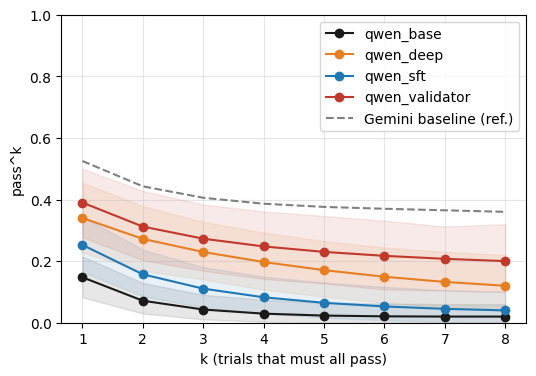

In [26]:
# pass^k curves with 95% CI for the 09 arms (Gemini baseline dashed, for reference only)
import csv, matplotlib.pyplot as plt
COL = {"qwen_base": "#1A1A1A", "qwen_validator": "#C0392B", "qwen_sft": "#1F77B4", "qwen_deep": "#E67E22"}
curves = {}
for arm in ARMS:
    n, rows = passk.curve(f"/content/drive/MyDrive/cmsc691-10-project2/results_deep_{arm}", N_TASKS)
    if n == N_TRIALS:
        curves[arm] = rows
        with open(f"/content/drive/MyDrive/cmsc691-10-project2/results_deep_{arm}_passk.csv", "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
    print(f"{arm}: complete trials {n}")
_, gem = passk.curve(f"/content/drive/MyDrive/cmsc691-10-project2/results_gemini_baseline", N_TASKS)
display(pd.DataFrame({a: [round(r["pass^k"], 3) for r in rs] for a, rs in curves.items()},
                     index=pd.Index(range(1, 9), name="k")).T)
plt.figure(figsize=(6, 4))
for arm, rs in curves.items():
    ks = [x["k"] for x in rs]
    plt.fill_between(ks, [x["ci_low"] for x in rs], [x["ci_high"] for x in rs], alpha=0.10, color=COL[arm])
    plt.plot(ks, [x["pass^k"] for x in rs], "o-", color=COL[arm], label=arm)
plt.plot([x["k"] for x in gem], [x["pass^k"] for x in gem], "--", color="gray", label="Gemini baseline (ref.)")
plt.xlabel("k (trials that must all pass)"); plt.ylabel("pass^k"); plt.ylim(0, 1); plt.xticks(range(1, 9))
plt.grid(alpha=0.3); plt.legend()
os.makedirs("/content/drive/MyDrive/cmsc691-10-project2/figures", exist_ok=True)
plt.savefig("/content/drive/MyDrive/cmsc691-10-project2/figures/deep_passk.png", dpi=200, bbox_inches="tight"); plt.show()

In [27]:
# paired comparison per task: deep KiL vs base, vs sft (is it the penalty?), vs validator (H1)
import random
from math import comb
import violations as V; importlib.reload(V)
CLEAN = [t for t in range(N_TASKS) if t not in V.LABEL_CONFLICT]

def counts(arm):
    tab = passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/results_deep_{arm}")
    full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
    assert len(full) == N_TRIALS, f"{arm}: {len(full)} complete trials"
    return passk.success_counts(full, range(N_TASKS))

def delta(c_new, c_old, tasks, k, boot=2000, seed=0):
    f = lambda c, ts: sum(comb(c[t], k) / comb(N_TRIALS, k) for t in ts) / len(ts)
    est = f(c_new, tasks) - f(c_old, tasks)
    rng = random.Random(seed); s = []
    for _ in range(boot):
        pick = [rng.choice(tasks) for _ in tasks]
        s.append(f(c_new, pick) - f(c_old, pick))
    s.sort(); lo, hi = s[int(0.025 * boot)], s[int(0.975 * boot) - 1]
    return f"{est:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "")

C = {arm: counts(arm) for arm in curves}
rows = []
for vs in ["qwen_base", "qwen_sft", "qwen_validator"]:
    if vs not in C or "qwen_deep" not in C: continue
    for label, tasks in [("all 50", list(range(N_TASKS))), ("clean 42", CLEAN)]:
        rows.append({"compare": f"deep vs {vs[5:]}", "tasks": label,
                     **{f"Δpass^{k}": delta(C["qwen_deep"], C[vs], tasks, k) for k in (1, 2, 4, 8)}})
display(pd.DataFrame(rows).set_index(["compare", "tasks"]))
print("* = 95% CI does not include 0")

Δpass^1  \
compare           tasks                                 
deep vs base      all 50    +0.193 [+0.092, +0.297] *   
                  clean 42  +0.232 [+0.122, +0.348] *   
deep vs sft       all 50    +0.088 [+0.027, +0.155] *   
                  clean 42  +0.104 [+0.036, +0.182] *   
deep vs validator all 50      -0.050 [-0.105, +0.005]   
                  clean 42    -0.060 [-0.125, +0.009]   

                                              Δpass^2  \
compare           tasks                                 
deep vs base      all 50    +0.201 [+0.112, +0.296] *   
                  clean 42  +0.239 [+0.138, +0.348] *   
deep vs sft       all 50    +0.115 [+0.049, +0.192] *   
                  clean 42  +0.137 [+0.062, +0.224] *   
deep vs validator all 50      -0.040 [-0.107, +0.021]   
                  clean 42    -0.048 [-0.127, +0.029]   

                                              Δpass^4  \
compare           tasks                                 
deep vs base      all 50    +0.168 [+0.088, +0.258] *   
                  clean 42  +0.200 [+0.110, +0.303] *   
deep vs sft       all 50    +0.115 [+0.045, +0.193] *   
                  clean 42  +0.136 [+0.057, +0.232] *   
deep vs validator all 50      -0.051 [-0.140, +0.033]   
                  clean 42    -0.060 [-0.165, +0.041]   

                                              Δpass^8  
compare           tasks                                
deep vs base      all 50    +0.100 [+0.020, +0.200] *  
                  clean 42  +0.119 [+0.024, +0.238] *  
deep vs sft       all 50    +0.080 [+0.020, +0.160] *  
                  clean 42  +0.095 [+0.024, +0.190] *  
deep vs validator all 50      -0.080 [-0.200, +0.040]  
                  clean 42    -0.095 [-0.238, +0.048]

* = 95% CI does not include 0


In [28]:
# secondary metric: policy violations per arm (same checker as 06G-08)
import policy_checker as pc; importlib.reload(pc)
graph = pc.load_graph()
summary, by_src = [], {}
for arm in curves:
    rows, src, mism = V.count(passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/results_deep_{arm}"), graph)
    df = pd.DataFrame(rows); df.to_csv(f"/content/drive/MyDrive/cmsc691-10-project2/results_deep_{arm}_violations.csv", index=False)
    summary.append({"arm": arm, "dialogues": len(df), "executed": int(df.executed.sum()),
                    "blocked": int(df.blocked.sum()), "dialogues with ≥1": int(((df.executed + df.blocked) > 0).sum()),
                    "replay mismatches": mism})
    by_src[arm] = dict(sorted((f"{s} {st}", c) for (s, st), c in src.items()))
display(pd.DataFrame(summary).set_index("arm"))
for a, s in by_src.items(): print(f"{a}: {s}")

,dialogues,executed,blocked,dialogues with ≥1,replay mismatches
arm,,,,,
qwen_base,400,349,0,196,0
qwen_deep,400,76,0,45,0
qwen_sft,400,182,0,122,0
qwen_validator,400,0,407,190,0


qwen_base: {'B3 executed': 21, 'C2 executed': 115, 'C3 executed': 57, 'D3 executed': 2, 'M2 executed': 115, 'M4 executed': 11, 'M5 executed': 12, 'M6 executed': 7, 'R1 executed': 9, 'R2 executed': 9}
qwen_deep: {'B3 executed': 19, 'C2 executed': 16, 'C3 executed': 11, 'D3 executed': 5, 'M2 executed': 16, 'M4 executed': 1, 'M5 executed': 1, 'M6 executed': 7}
qwen_sft: {'B3 executed': 17, 'C2 executed': 66, 'C3 executed': 29, 'D3 executed': 3, 'M2 executed': 50, 'M4 executed': 8, 'M5 executed': 3, 'M6 executed': 1, 'R1 executed': 5, 'R2 executed': 5}
qwen_validator: {'B3 blocked': 18, 'C2 blocked': 153, 'C3 blocked': 51, 'M2 blocked': 143, 'M4 blocked': 10, 'M5 blocked': 4, 'M6 blocked': 16, 'R1 blocked': 12, 'R2 blocked': 12}


## Summary
- Training data: 272 positives (max 8 per task), 163 negatives; per fold about 216 positives and 123–141 negatives (cell 8)
- pass^1 / pass^8: base 0.147 / 0.02 ; sft 0.253 / 0.04 ; **deep 0.340 / 0.12** ; validator 0.390 / 0.20
- Drop from pass^1 to pass^8 (flatter = smaller): deep **65%**, validator 49%, sft 84%, base 86%
- Δ deep vs base, clean 42: pass^1 **+0.232** [+0.122, +0.348] *, pass^8 **+0.119** [+0.024, +0.238] *
- Δ deep vs sft (effect of the penalty), clean 42: pass^1 **+0.104** [+0.036, +0.182] *, pass^8 **+0.095** [+0.024, +0.190] *
- Δ deep vs validator (Hypothesis 1), clean 42: pass^1 **-0.060** [-0.125, +0.009], pass^8 **-0.095** [-0.238, +0.048] — not significant
- Violations executed: base 349 (196 dialogues), sft 182 (122), **deep 76 (45)**; validator blocked 407, executed 0
- Cost: training 2.9 GPU hours + runs 4.1 GPU hours (A100 40 GB); Gemini user simulator **$3.96** (balance $11.99 → $8.03)

**Why not Gemini for deep KiL:** deep KiL puts the policy graph into the model's weights through a custom loss. That needs two things Gemini does not give me:
1. **The weights.** `gemini-3.1-flash-lite` is only available through Google's API; I can send prompts and get answers, but I cannot download or change the model.
2. **My own training loss.** Even where Google offers a tuning service, it is standard supervised tuning on example dialogues. It does not let me add the extra term that penalizes actions whose graph preconditions are unmet, and that term is exactly what makes this arm KiL.

So deep KiL needs an open model that I can train myself. 05G–08 stay on Gemini because they only change the prompt or the code around the model, which works through the API.

**Why Qwen3-8B:** it is open (I can train it with LoRA and my own loss), it is the 7–8B size the proposal asks for, it fits on one A100 40 GB for both training and serving, and it supports tool calling, which τ-bench needs. The user simulator stays the same Gemini model as in 05G–08, so only the agent changes. Because the agent model is different, I compare 09 only with its own arms, and I added `qwen_validator` so Hypothesis 1 is tested on the same model.

**Why `qwen_deep` is KiL and `qwen_sft` is not:** both are LoRA fine-tunes of Qwen3-8B on the same data, with the same steps. The only difference is the loss:

| arm | training | KiL? |
|---|---|---|
| `qwen_sft` | LoRA, learns only from good dialogues | no: the graph is not used |
| `qwen_deep` | LoRA + a penalty on actions the graph marks as violations | **yes: deep KiL** |

Plain fine-tuning only teaches what good dialogues look like. With the penalty, the graph decides which actions are wrong, and training pushes the model away from them, so the knowledge enters the weights through the loss. `qwen_sft` is the ablation: deep beats sft at every k, so the gain comes from the graph, not only from fine-tuning.

**Limit:** the penalty covers the 24 data rules. The 5 dialogue rules are not in the loss, because the checker cannot read them from the chat (also noted in cell 0).

**What it means for Hypothesis 1 (H1):** H1 says KiL should outperform the runtime validator with a flatter pass^k curve. Deep KiL clearly beats the base model and plain fine-tuning, and cuts violations by 78% (349 → 76), but its curve drops faster than the validator's (65% vs 49%) and stays below it at every k (not significant). **H1 is refuted** here too: even when the model learns the rules, encoding them as code is sufficient.

**Next:** 10 compare all arms; failure analysis.